# Split test: the default CNN against smaller ones, without pre-training

`znn.build_model` has 1.34M parameters for inputs of shape (32, 3), 88% of them in its last two convolutions, which run on sequences of length 4. LeNet-5 has about 60k on a 32×32 image. Two smaller alternatives:
- `znn.build_model_v2` (557k parameters): the same channels, but one 512-channel convolution instead of two, after a fourth pooling (so on a sequence of length 2);
- `znn.build_model_small`, LeNet-sized (about 22k parameters): channels 16-32-64-64 instead of 32-…-512, and a 32-unit dense layer.

Both are trained with the newest defaults of the task-set notebooks, `znn.train_from_catalog` with:

| setting | value |
|---|---|
| `from_base` | True: one base model on all the objects, then 10 copies fine-tuned on their own noise realization and K-fold cut |
| `N_MEMBERS` | 10 |
| `FINETUNE_EPOCHS`, `FINETUNE_LR` | 10 epochs at a constant 3e-4 |
| `pretraining` | **None** (the base model starts from scratch), so both architectures start equal: the pop-cosmos weights only exist for `build_model` |

| ensemble | architecture | start |
|---|---|---|
| `default` | `znn.build_model` (1.34M) | scratch |
| `v2` | `znn.build_model_v2` (557k) | scratch |
| `small` | `znn.build_model_small` (22k) | scratch |
| `popcosmos_default` | `znn.build_model` (1.34M) | pop-cosmos; the `frombase_kfold10_lr3e-4` ensemble of the previous split test (commit 71e5883), trained with the same settings, loaded from its saved file |

The question is whether a smaller model scores as well as the default one; `popcosmos_default` shows how much of the result the pre-training is worth. With the first `N_FROZEN_LAYERS` layers frozen in the fine-tuning, the members of `default` re-train 99.5% of their parameters, those of `v2` 98.8% and those of `small` 92%.

Everything is on the configuration that degraded most (task set 3, cardinal, 10yr), scored on the same held-out objects (the `VAL_FRAC`, `SEED` split of the task-set notebooks, never used in training) and predicted the same way: `znn.predict_from_catalog` with `N_SAMPLES` noise draws from the same seed, giving a Gaussian p(z) per object. An earlier split test (commit f881508) found that retraining with identical settings moves the scatter by about 5% and KS by about 15%: treat differences smaller than that as noise.

Run this from the repo root on NERSC with the `qp` conda env as the kernel. Trained models, their training times and the predictions are saved in `TEST_DIR`, so a rerun skips what is done.

## Configuration

In [1]:
import os

from rail.utils.path_utils import find_rail_file

import znn  # run from the repo root so this picks up the local source

# the configuration that degraded most in the noisytrain run
TASKSET, SIM, SCENARIO = 3, "cardinal", "10yr"
DATA_DIR = "../pz_data_challenge/scripts/public"  # as in the task-set notebooks

MODEL_NAME = f"pz_challenge_taskset_{TASKSET}_{SIM}_pz_model_{SCENARIO}.pkl"

# Saved ensembles to re-evaluate: name -> candidate model files (the first that exists is used); a training time
# is shown if "<name>_train_time.json" sits next to it
SAVED = {
    "popcosmos_default": [f"outputs/frombase_test_taskset_{TASKSET}_{SIM}_{SCENARIO}/frombase_kfold10_lr3e-4_{MODEL_NAME}"],
}
# Ensembles trained here: name -> architecture
TRAIN = {
    "default": znn.build_model,
    "v2": znn.build_model_v2,
    "small": znn.build_model_small,
}
REFERENCE = "default"  # the relative columns of the summary table are against this ensemble
TEST_DIR = f"outputs/model_size_test_taskset_{TASKSET}_{SIM}_{SCENARIO}"  # models trained here, their times, predictions

# the newest defaults of the task-set notebooks, without pre-training
PRETRAINING = None
FROM_BASE = True
N_MEMBERS = 10
EPOCHS = 100  # max epochs of the base model
FINETUNE_EPOCHS = 10  # epochs of each fine-tuned member
FINETUNE_LR = 3e-4
VAL_FRAC = 0.2  # the held-out split (and the base model's early-stopping fraction)
SEED = 42
NOISE_SEED = 42  # seed of the training noise realizations
# as in pz_challenge_results.ipynb
N_SAMPLES = 50
PREDICT_SEED = 42

FILTER_DIR = find_rail_file("examples_data/estimation_data/data/FILTER")
BANDS = {
    "u": ("mag_u_lsst", f"{FILTER_DIR}/DC2LSST_u.res"),
    "g": ("mag_g_lsst", f"{FILTER_DIR}/DC2LSST_g.res"),
    "r": ("mag_r_lsst", f"{FILTER_DIR}/DC2LSST_r.res"),
    "i": ("mag_i_lsst", f"{FILTER_DIR}/DC2LSST_i.res"),
    "z": ("mag_z_lsst", f"{FILTER_DIR}/DC2LSST_z.res"),
    "y": ("mag_y_lsst", f"{FILTER_DIR}/DC2LSST_y.res"),
    "Y": ("mag_Y_roman", f"{FILTER_DIR}/roman_Y106.res"),
    "J": ("mag_J_roman", f"{FILTER_DIR}/roman_J129.res"),
    "H": ("mag_H_roman", f"{FILTER_DIR}/roman_H158.res"),
}
REF_BAND = "i"
FEATURE_CONFIG = znn.DEFAULT_FEATURE_CONFIG
ERRORS = {col: f"{col}_err" for col, _ in BANDS.values()}

I0000 00:00:1793227203.368135   55198 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qp
from qp.metrics.pit import PIT
from sklearn.model_selection import train_test_split

from pz_data_challenge import scoring

os.makedirs(TEST_DIR, exist_ok=True)

SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    # Reference redshift per training object, and the held-out subsets to score (as in pz_challenge_results.ipynb).
    z_spec = train["redshift"].to_numpy()
    if "COSMOS" not in train:  # task sets 1 and 2
        subsets = {"all": np.ones(len(train), dtype=bool)}
        if (train["mag_i_lsst"] < 23.5).all():
            return z_spec, subsets  # task set 1
        return z_spec, subsets | {"i > 23": train["mag_i_lsst"].to_numpy() > 23}  # task set 2

    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos_only = train["COSMOS"].astype(bool).to_numpy() & ~is_spec
    z_ref = np.where(is_cosmos_only, train["redshift_manyband"].to_numpy(), z_spec)
    assert np.isfinite(z_ref).all()
    return z_ref, {"all": np.ones(len(train), dtype=bool), "spec": is_spec, "COSMOS-only": is_cosmos_only}


train = znn.read_catalog(os.path.join(DATA_DIR, f"pz_challenge_taskset_{TASKSET}_{SIM}_training_{SCENARIO}.hdf5"))
z_ref, subsets = reference_redshifts(train)
idx_fit, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
val = train.iloc[idx_val]
print(f"task set {TASKSET} {SIM} {SCENARIO}: {len(idx_fit)} objects to train on, {len(idx_val)} held out")

model_files = {}
for name, candidates in SAVED.items():
    found = [f for f in candidates if os.path.exists(f)]
    assert found, f"no saved {name} model in {candidates}"
    model_files[name] = found[0]
    print(f"{name}: {model_files[name]}")


def time_file(model_file):
    # where the training time of the ensemble saved in model_file is
    return model_file.replace(MODEL_NAME, "train_time.json")

task set 3 cardinal 10yr: 80000 objects to train on, 20000 held out
popcosmos_default: outputs/frombase_test_taskset_3_cardinal_10yr/frombase_kfold10_lr3e-4_pz_challenge_taskset_3_cardinal_pz_model_10yr.pkl


## Train

Each ensemble in `TRAIN` is trained on the fit split with `znn.train_from_catalog` and saved in `TEST_DIR`, with its wall-clock training time. An ensemble already saved there is loaded instead.

default: already trained, outputs/model_size_test_taskset_3_cardinal_10yr/default_pz_challenge_taskset_3_cardinal_pz_model_10yr.pkl

==================== v2: build_model_v2 ====================

=== Base model, on all objects with the photometry as given ===


/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1793227302.673398   55198 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38478 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:03:00.0, compute capability: 8.0
I0000 00:00:1793227302.683297   55198 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 38478 MB memory:  -> device: 1, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:41:00.0, compute capability: 8.0
I0000 00:00:1793227302.694083   55198 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:2 with 38478 MB memory:  -> device: 2, name: NVI

Epoch 1/100


I0000 00:00:1793227306.122349   55709 service.cc:153] XLA service 0x7f2890034500 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793227306.122375   55709 service.cc:161]   StreamExecutor [0]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793227306.122383   55709 service.cc:161]   StreamExecutor [1]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793227306.122387   55709 service.cc:161]   StreamExecutor [2]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793227306.122389   55709 service.cc:161]   StreamExecutor [3]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793227306.162941   55709 dump_mlir_util.cc:269] disabling MLIR crash repro

250/250 - 46s - 186ms/step - loss: 0.0103 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0068 - val_loss: 0.0040 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0060 - val_loss: 0.0040 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0057 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0054 - val_loss: 0.0035 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0053 - val_loss: 0.0034 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0052 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0051 - val_loss: 0.0035 - learning_rate: 0.0010
Epoch 9/100
250/250 - 1s - 3ms/step - loss: 0.0050 - val_loss: 0.0034 - learning_rate: 0.0010
Epoch 10/100

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0050 - val_loss: 0.0032 - learning_rat

...

282/282 - 7s - 24ms/step - loss: 0.0047 - val_loss: 0.0042
Epoch 2/10
282/282 - 1s - 2ms/step - loss: 0.0046 - val_loss: 0.0042
Epoch 3/10
282/282 - 1s - 2ms/step - loss: 0.0046 - val_loss: 0.0042
Epoch 4/10
282/282 - 1s - 2ms/step - loss: 0.0045 - val_loss: 0.0042
Epoch 5/10
282/282 - 1s - 2ms/step - loss: 0.0045 - val_loss: 0.0043
Epoch 6/10
282/282 - 1s - 2ms/step - loss: 0.0045 - val_loss: 0.0043
Epoch 7/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0043
Epoch 8/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0042
Epoch 9/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0044
Epoch 10/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0043

--- Member 9/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793227509.055233   55709 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_142415__.45
I0000 00:00:1793227511.176142   55707 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_142415__.45


282/282 - 7s - 24ms/step - loss: 0.0047 - val_loss: 0.0043
Epoch 2/10
282/282 - 1s - 2ms/step - loss: 0.0046 - val_loss: 0.0042
Epoch 3/10
282/282 - 1s - 2ms/step - loss: 0.0046 - val_loss: 0.0042
Epoch 4/10
282/282 - 1s - 2ms/step - loss: 0.0045 - val_loss: 0.0042
Epoch 5/10
282/282 - 1s - 2ms/step - loss: 0.0045 - val_loss: 0.0043
Epoch 6/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0043
Epoch 7/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0043
Epoch 8/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0043
Epoch 9/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0043
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0043

--- Member 10/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793227522.430278   55705 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_154781__.45
I0000 00:00:1793227524.621375   55706 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_154781__.45


282/282 - 7s - 24ms/step - loss: 0.0047 - val_loss: 0.0048
Epoch 2/10
282/282 - 1s - 2ms/step - loss: 0.0046 - val_loss: 0.0048
Epoch 3/10
282/282 - 1s - 2ms/step - loss: 0.0045 - val_loss: 0.0049
Epoch 4/10
282/282 - 1s - 2ms/step - loss: 0.0045 - val_loss: 0.0047
Epoch 5/10
282/282 - 1s - 2ms/step - loss: 0.0045 - val_loss: 0.0048
Epoch 6/10
282/282 - 1s - 2ms/step - loss: 0.0045 - val_loss: 0.0048
Epoch 7/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0048
Epoch 8/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0048
Epoch 9/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0048
Epoch 10/10
282/282 - 1s - 2ms/step - loss: 0.0044 - val_loss: 0.0047
v2: trained in 3.9 min


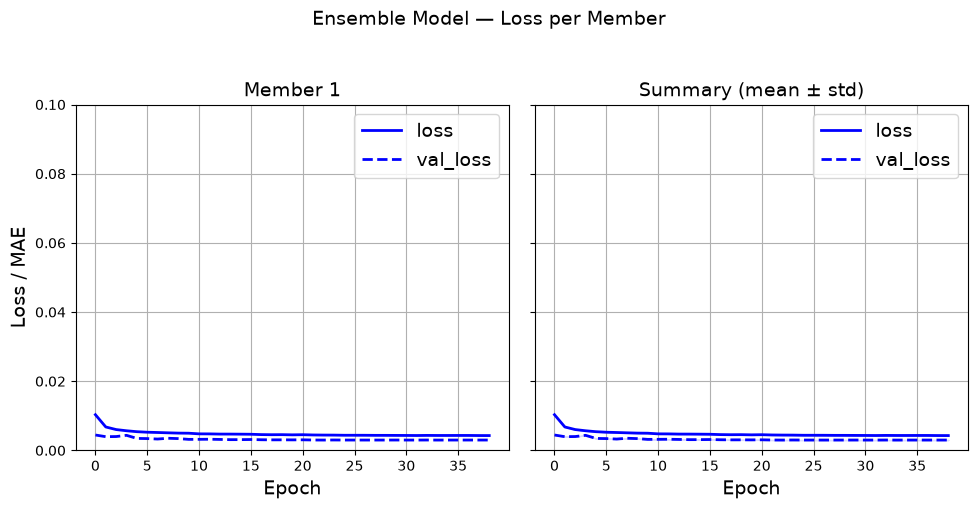

<Figure size 640x480 with 0 Axes>

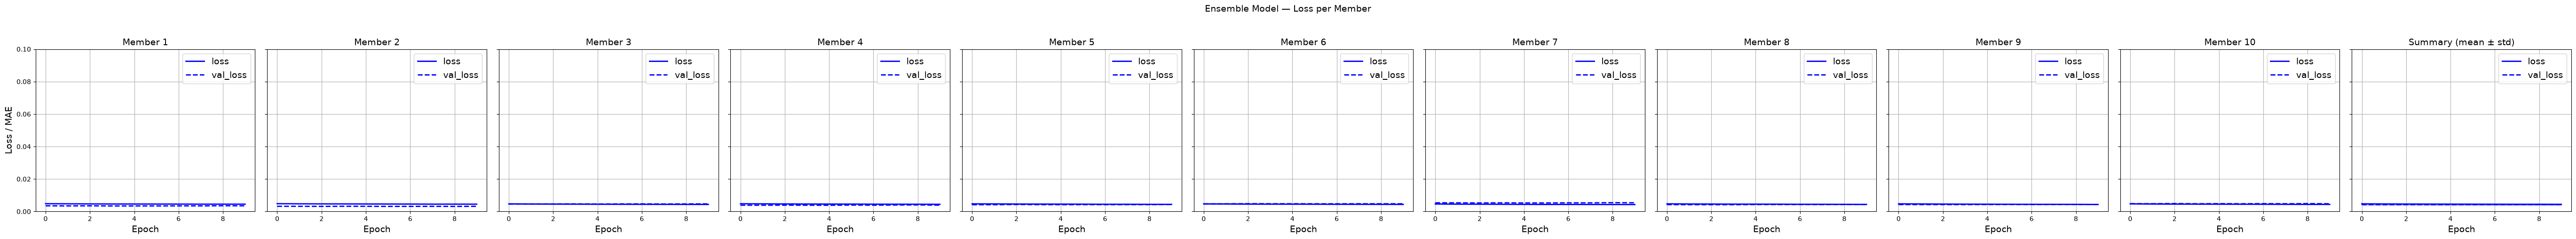

<Figure size 640x480 with 0 Axes>

small: already trained, outputs/model_size_test_taskset_3_cardinal_10yr/small_pz_challenge_taskset_3_cardinal_pz_model_10yr.pkl


In [3]:
train_minutes = {}
for name, build_model_func in TRAIN.items():
    model_files[name] = os.path.join(TEST_DIR, f"{name}_{MODEL_NAME}")
    if os.path.exists(model_files[name]) and os.path.exists(time_file(model_files[name])):
        print(f"{name}: already trained, {model_files[name]}")
        continue
    print(f"\n==================== {name}: {build_model_func.__name__} ====================")
    start = time.time()
    trained_models, histories, base_history = znn.train_from_catalog(
        build_model_func, train.iloc[idx_fit], z_ref[idx_fit], BANDS, REF_BAND, FEATURE_CONFIG, errors=ERRORS,
        rng=np.random.default_rng(NOISE_SEED), N_MEMBERS=N_MEMBERS, from_base=FROM_BASE, EPOCHS=EPOCHS,
        FINETUNE_EPOCHS=FINETUNE_EPOCHS, FINETUNE_LR=FINETUNE_LR, random_state=SEED, pretraining=PRETRAINING,
    )
    minutes = (time.time() - start) / 60
    json.dump({"minutes": minutes}, open(time_file(model_files[name]), "w"))
    znn.save_ensemble_file(model_files[name], trained_models, BANDS, REF_BAND, FEATURE_CONFIG)
    print(f"{name}: trained in {minutes:.1f} min")

    if base_history is not None:
        znn.plot_ensemble_losses([base_history], ylim=(0, 0.1))
        plt.suptitle(f"{name}: base model", y=1.08)
        plt.show()
    znn.plot_ensemble_losses(histories, ylim=(0, 0.1))
    plt.suptitle(name, y=1.08)
    plt.show()

for name, model_file in model_files.items():
    if os.path.exists(time_file(model_file)):
        train_minutes[name] = json.load(open(time_file(model_file)))["minutes"]

## Predict the held-out objects

Every ensemble with the same `N_SAMPLES` noise draws (same seed). Cached in `TEST_DIR`.

In [4]:
def heldout_predictions(name):
    # Per held-out object: p(z) mean and std, and the std split into members' disagreement and noise draws.
    cache = os.path.join(TEST_DIR, f"heldout_{name}.npz")
    if os.path.exists(cache):
        return dict(np.load(cache))
    trained_models, features = znn.load_ensemble_file(model_files[name])
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz, components = znn.predict_from_catalog(
        trained_models, val, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(PREDICT_SEED),
        return_components=True,
    )
    out = {
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
        "model_std": components["model"],
        "photometric_std": components["photometric"],
    }
    np.savez(cache, **out)
    return out


ARMS = list(SAVED) + list(TRAIN)
preds = {}
for name in ARMS:
    print("held-out predictions:", name)
    preds[name] = heldout_predictions(name)

held-out predictions: popcosmos_default
held-out predictions: default
held-out predictions: v2
held-out predictions: small


## Scores

The challenge's seven metrics (as in `pz_challenge_results.ipynb`, with the mean as the point estimate) and their tier points, per ensemble and held-out subset, plus:
- `width/scatter`: median p(z) σ/(1+z) over the biweight scatter; 1 for p(z)s as wide as the actual errors, below 1 for overconfident ones;
- `model σ`, `photometric σ`: median of the two parts of the p(z) σ (they add in quadrature). `model σ` measures how different the members are;
- `pit_outlier_direct`: the PIT outlier rate computed directly (the scored `outlier` comes from a spline fit that breaks down when PIT piles up at 0 or 1).

Lower is better for all metrics except the points. Remember the run-to-run noise of about 5% in scatter and 15% in KS.

In [5]:
def scores(z, d, m):
    dz = (d["mean"][m] - z[m]) / (1 + z[m])
    bias, _, scatter, _, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier(dz)
    pz = qp.Ensemble(qp.stats.norm, data={"loc": d["mean"][m, None], "scale": d["std"][m, None]})
    pit = PIT(pz, z[m])
    values = {
        "mean": bias,
        "std": scatter,
        "abs_outlier_rate": abs_outlier_rate,
        "ks": pit.evaluate_PIT_KS().statistic,
        "CvM": pit.evaluate_PIT_CvM().statistic,
        "ksamp": pit.evaluate_PIT_anderson_ksamp().statistic,
        "outlier": pit.evaluate_PIT_outlier_rate(),
    }
    points = sum(lo <= float(values[k]) <= hi for k, ranges in scoring.metric_dict.items() for lo, hi in ranges)
    extra = {
        "pit_outlier_direct": np.mean((pit.pit_samps < 0.0001) | (pit.pit_samps > 0.9999)),
        "width/scatter": np.median(d["std"][m] / (1 + z[m])) / scatter,
        "model σ": np.median(d["model_std"][m]),
        "photometric σ": np.median(d["photometric_std"][m]),
        "points": points,
    }
    return values | extra, pit.pit_samps


z_val = z_ref[idx_val]
rows, pits = {}, {}
for name in ARMS:
    for subset, mask in subsets.items():
        rows[(subset, name)], pits[(subset, name)] = scores(z_val, preds[name], mask[idx_val])

table = pd.DataFrame(rows).T
table.index.names = ["subset", "ensemble"]
n_max = sum(len(r) for r in scoring.metric_dict.values())
print(f"points out of {n_max}")
table.round(4)

/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


points out of 21


,,mean,std,abs_outlier_rate,ks,CvM,ksamp,outlier,pit_outlier_direct,width/scatter,model σ,photometric σ,points
subset,ensemble,,,,,,,,,,,,
all,popcosmos_default,0.0006,0.0182,0.0259,0.0640,35.6009,219.2741,4.907100e+00,0.0323,0.7543,0.0176,0.0143,17.0
spec,popcosmos_default,0.0002,0.0126,0.0011,0.0350,4.5031,32.5316,1.400000e-03,0.0054,0.8222,0.0136,0.0098,21.0
COSMOS-only,popcosmos_default,0.0048,0.0486,0.0690,0.1400,54.8107,276.4592,-2.154717e+10,0.0791,0.6600,0.0352,0.0462,16.0
all,default,0.0023,0.0205,0.0260,0.1125,108.7219,514.6298,-2.624340e+01,0.0412,0.7148,0.0178,0.0140,17.0
spec,default,0.0022,0.0148,0.0011,0.1007,51.7029,211.7103,9.000000e-03,0.0146,0.7128,0.0138,0.0096,21.0
COSMOS-only,default,0.0041,0.0504,0.0691,0.1592,67.1079,340.4511,-2.052085e+12,0.0876,0.6102,0.0323,0.0442,15.0
all,v2,0.0059,0.0207,0.0265,0.1723,270.7064,947.3289,1.463600e+00,0.0342,0.7981,0.0226,0.0144,16.0
spec,v2,0.0055,0.0148,0.0009,0.1797,198.5917,635.3611,1.300000e-03,0.0047,0.8404,0.0176,0.0101,21.0
COSMOS-only,v2,0.0092,0.0498,0.0709,0.1816,94.9514,410.8291,-1.845421e+12,0.0854,0.6283,0.0350,0.0447,16.0


In [6]:
# the key numbers on all held-out objects, relative to REFERENCE, with model sizes and training times
key = ["std", "abs_outlier_rate", "ks", "width/scatter", "model σ", "points"]
rel = table.xs("all", level="subset")[key].copy()
rel["parameters"] = pd.Series({name: znn.load_ensemble_file(f)[0][0][0].count_params() for name, f in model_files.items()})
rel["train time [min]"] = pd.Series(train_minutes)
for col in ["std", "abs_outlier_rate", "ks", "model σ"]:
    rel[f"{col} vs {REFERENCE}"] = rel[col] / rel.loc[REFERENCE, col] - 1
rel.round(4)

,std,abs_outlier_rate,ks,width/scatter,model σ,points,parameters,train time [min],std vs default,abs_outlier_rate vs default,ks vs default,model σ vs default
ensemble,,,,,,,,,,,,
popcosmos_default,0.0182,0.0259,0.0640,0.7543,0.0176,17.0,1343361,3.6296,-0.1116,-0.0019,-0.4312,-0.0123
default,0.0205,0.0260,0.1125,0.7148,0.0178,17.0,1343361,3.7916,0.0000,0.0000,0.0000,0.0000
v2,0.0207,0.0265,0.1723,0.7981,0.0226,16.0,556417,3.9076,0.0078,0.0212,0.5310,0.2658
small,0.0260,0.0303,0.1748,0.5885,0.0172,15.0,22401,2.9699,0.2679,0.1676,0.5534,-0.0354


## PIT

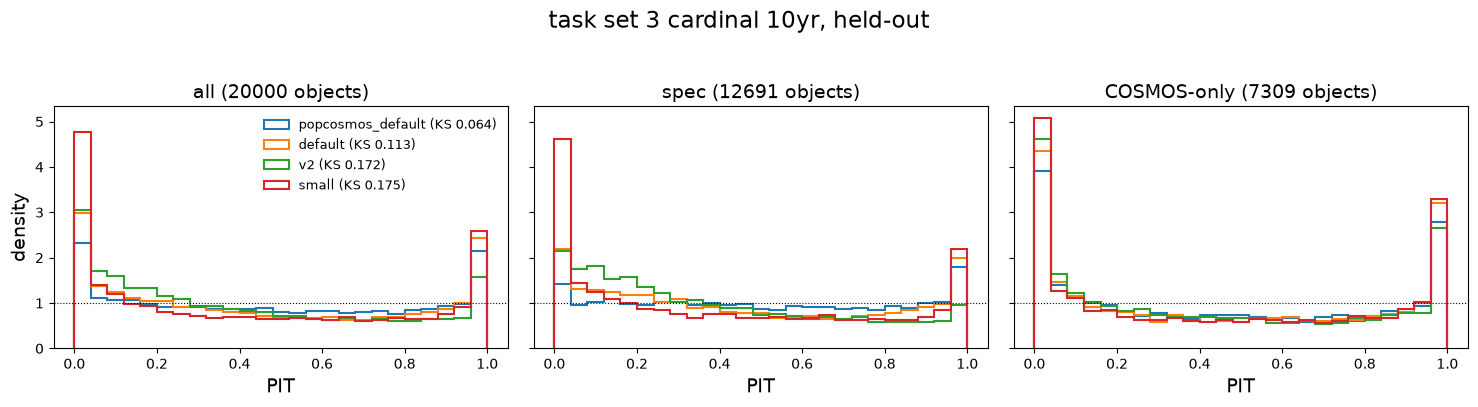

In [7]:
pit_bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(1, len(subsets), figsize=(5 * len(subsets), 4), sharey=True, squeeze=False)
for ax, subset in zip(axes[0], subsets):
    for name in ARMS:
        ax.hist(pits[(subset, name)], pit_bins, density=True, histtype="step", lw=1.5,
                label=f"{name} (KS {table.loc[(subset, name), 'ks']:.3f})")
    ax.axhline(1, color="k", lw=0.8, ls=":")
    ax.set_title(f"{subset} ({subsets[subset][idx_val].sum()} objects)")
    ax.set_xlabel("PIT")
axes[0, 0].set_ylabel("density")
axes[0, 0].legend(fontsize=9, frameon=False)
fig.suptitle(f"task set {TASKSET} {SIM} {SCENARIO}, held-out", y=1.02)
fig.tight_layout()
plt.show()